# Phishing Website Detection

A machine learning project that classifies websites as **phishing** or **legitimate** from 30 extracted website characteristics, such as HTTPS usage, anchor-link behaviour, domain registration length and traffic indicators.

**Objective:** build a reliable classifier that catches as many phishing websites as possible, and package it so it can score new websites.

**Dataset:** 11,054 websites, each described by 30 pre-extracted numeric indicators (encoded as -1, 0 or +1), with a target label: -1 = phishing, +1 = legitimate.

**Approach:** data validation and exploration, leakage-safe preprocessing in pipelines, a stratified train/test split, five-fold cross-validation of three models, hyperparameter tuning optimised for phishing recall, a single final evaluation on untouched test data, and saving the fitted model for reuse.

> For educational purposes only. This model should not be the sole defence against phishing.

## 1. Import libraries and set reproducibility

Import the data, visualisation and scikit-learn tools, and fix `RANDOM_STATE = 42` so every split, fold and model gives repeatable results. The label convention (-1 = phishing, +1 = legitimate) is defined once here and reused throughout.

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, GridSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer)

RANDOM_STATE = 42
TARGET = "class"
IDENTIFIER_COLUMNS = ["Index"]
PHISHING_LABEL = -1  # Dataset convention: -1 = phishing, +1 = legitimate
class_names = {PHISHING_LABEL: "Phishing", 1: "Legitimate"}


## 2. Load and inspect the CSV

Load `phishing.csv` with a guard that raises a clear error if the file is missing, then review the shape, column names, data types and structure.

**Findings:** 11,054 rows and 32 columns, all stored as integers.

In [3]:
DATA_PATH = Path("phishing.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place phishing.csv in the same folder as this notebook.")

df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())


Rows: 11,054 | Columns: 32


,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


In [4]:
print("Column names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nDataset information:")
df.info()


Column names:
['Index', 'UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon', 'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL', 'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick', 'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording', 'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage', 'StatsReport', 'class']

Data types:


,dtype
Index,int64
UsingIP,int64
LongURL,int64
ShortURL,int64
Symbol@,int64
Redirecting//,int64
PrefixSuffix-,int64
SubDomains,int64
HTTPS,int64
DomainRegLen,int64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormH

## 3. Target, missing values, duplicate rows, and feature types

Validate data quality before modelling: class balance, missing values, exact duplicate rows and feature types.

**Findings:**
- Classes are reasonably balanced: 55.7% legitimate (6,157) and 44.3% phishing (4,897), so no resampling is needed.
- No missing values and no duplicate rows.
- All 30 predictors are numeric.

In [5]:
if TARGET not in df.columns:
    raise ValueError(f"Target column {TARGET!r} is not present.")

FEATURE_COLUMNS = [c for c in df.columns if c != TARGET and c not in IDENTIFIER_COLUMNS]

print("Target counts:")
display(df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("count"))
print("\nTarget proportions:")
display(df[TARGET].value_counts(normalize=True).rename_axis(TARGET).to_frame("proportion"))
print("\nMissing values by column:")
display(df.isna().sum().rename("missing_count").to_frame())
print(f"\nExact duplicate rows: {df.duplicated().sum():,}")
print("\nFeature data types:")
display(df.drop(columns=[TARGET] + [c for c in IDENTIFIER_COLUMNS if c in df]).dtypes.value_counts().rename("column_count").to_frame())


Target counts:


,count
class,
1,6157
-1,4897



Target proportions:


,proportion
class,
1,0.556993
-1,0.443007



Missing values by column:


,missing_count
Index,0
UsingIP,0
LongURL,0
ShortURL,0
Symbol@,0
Redirecting//,0
PrefixSuffix-,0
SubDomains,0
HTTPS,0
DomainRegLen,0



Exact duplicate rows: 0

Feature data types:


,column_count
int64,30


## 4. Dataset suitability and column inventory

Check whether the data contains raw URL text and document the role of every column (target, excluded identifier, or predictor).

**Findings:** the columns with URL in their name are engineered indicators, not URL strings. The model therefore classifies websites from extracted features, not from raw URLs. `Index` is a row identifier and is excluded so the model cannot learn from it.

In [6]:
url_like = [c for c in df.columns if "url" in c.lower()]
raw_url_columns = [c for c in url_like if df[c].dtype == "object"]
print("URL-named columns:", url_like)
print("Raw URL text columns:", raw_url_columns)
print("\nThis dataset contains engineered website indicators; it does not provide URL strings to parse.")

column_inventory = pd.DataFrame({
    "column": df.columns,
    "role": ["target" if c == TARGET else "excluded identifier" if c in IDENTIFIER_COLUMNS else "predictor" for c in df.columns],
    "dtype": [str(df[c].dtype) for c in df.columns],
    "unique_values": [df[c].nunique(dropna=False) for c in df.columns],
})
display(column_inventory)


URL-named columns: ['LongURL', 'ShortURL', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL', 'AbnormalURL']
Raw URL text columns: []

This dataset contains engineered website indicators; it does not provide URL strings to parse.


,column,role,dtype,unique_values
0,Index,excluded identifier,int64,11054
1,UsingIP,predictor,int64,2
2,LongURL,predictor,int64,3
3,ShortURL,predictor,int64,2
4,Symbol@,predictor,int64,2
5,Redirecting//,predictor,int64,2
6,PrefixSuffix-,predictor,int64,2
7,SubDomains,predictor,int64,3
8,HTTPS,predictor,int64,3
9,DomainRegLen,predictor,int64,2


## 5. Exploratory data analysis

Summarise each feature statistically, then visualise the class balance, feature value distributions and the relationship between each feature and the target.

In [7]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Index,11054.0,5526.500000,3191.159272,0.0,2763.25,5526.5,8289.75,11053.0
UsingIP,11054.0,0.313914,0.949495,-1.0,-1.00,1.0,1.00,1.0
LongURL,11054.0,-0.633345,0.765973,-1.0,-1.00,-1.0,-1.00,1.0
ShortURL,11054.0,0.738737,0.674024,-1.0,1.00,1.0,1.00,1.0
Symbol@,11054.0,0.700561,0.713625,-1.0,1.00,1.0,1.00,1.0
Redirecting//,11054.0,0.741632,0.670837,-1.0,1.00,1.0,1.00,1.0
PrefixSuffix-,11054.0,-0.734938,0.678165,-1.0,-1.00,-1.0,-1.00,1.0
SubDomains,11054.0,0.064049,0.817492,-1.0,-1.00,0.0,1.00,1.0
HTTPS,11054.0,0.251040,0.911856,-1.0,-1.00,1.0,1.00,1.0
DomainRegLen,11054.0,-0.336711,0.941651,-1.0,-1.00,-1.0,1.00,1.0


### Class balance

A bar chart of how many phishing and legitimate websites are in the dataset.

C:\Users\king\AppData\Local\Temp\ipykernel_15556\2755272548.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


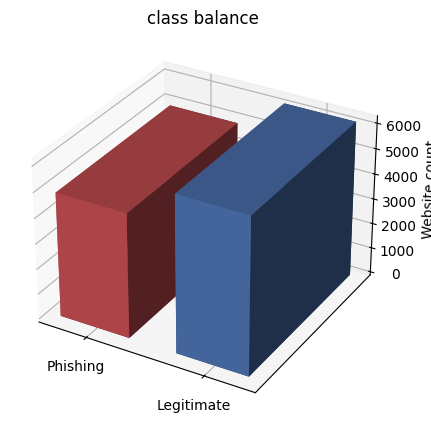

In [8]:
counts = df[TARGET].map(class_names).value_counts().reindex(["Phishing", "Legitimate"])
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
x = np.arange(len(counts))
ax.bar3d(x, np.zeros(len(x)), np.zeros(len(x)), 0.6, 0.6, counts.values, color=["#c44e52", "#4c72b0"], shade=True)
ax.set_xticks(x + 0.3); ax.set_xticklabels(counts.index)
ax.set_yticks([]); ax.set_zlabel("Website count")
ax.set_title("class balance")
plt.tight_layout(); plt.show()


### Feature value distributions

Show how often each encoded value (-1, 0, +1) appears for every feature, to understand how the indicators are spread.

C:\Users\king\AppData\Local\Temp\ipykernel_15556\3092853227.py:15: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


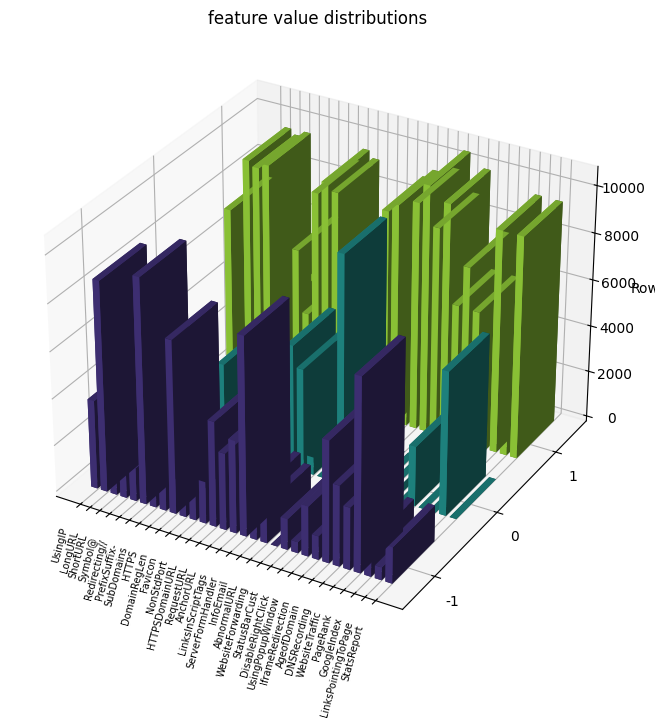

In [9]:
# 3D bars: feature on x, encoded value on y, number of rows on z.
values = sorted(set().union(*(set(df[c].dropna().unique()) for c in FEATURE_COLUMNS)))
xx, yy, heights = [], [], []
for i, feature in enumerate(FEATURE_COLUMNS):
    counts = df[feature].value_counts()
    for j, value in enumerate(values):
        xx.append(i); yy.append(j); heights.append(counts.get(value, 0))
fig = plt.figure(figsize=(15, 8)); ax = fig.add_subplot(111, projection="3d")
palette = plt.cm.viridis(np.linspace(0.15, 0.85, len(values)))
colors = [palette[j] for j in yy]
ax.bar3d(xx, yy, np.zeros(len(heights)), 0.65, 0.65, heights, color=colors, shade=True)
ax.set_xticks(np.arange(len(FEATURE_COLUMNS)) + 0.3); ax.set_xticklabels(FEATURE_COLUMNS, rotation=75, ha="right", fontsize=7)
ax.set_yticks(np.arange(len(values)) + 0.3); ax.set_yticklabels(values)
ax.set_zlabel("Rows"); ax.set_title("feature value distributions")
plt.tight_layout(); plt.show()


### Feature relationship to target

Rank features by their correlation with the class label (+1 = legitimate), to see which indicators carry the most signal.

**Findings:** `HTTPS` (0.71) and `AnchorURL` (0.69) have by far the strongest relationships with the class, followed by `PrefixSuffix-`, `WebsiteTraffic` and `SubDomains`. `DomainRegLen` is the strongest in the opposite direction (-0.23). Many features are individually weak, which is why a model that combines them performs better than any single indicator.

,correlation_with_class
DomainRegLen,-0.225879
ShortURL,-0.067931
AbnormalURL,-0.060751
HTTPSDomainURL,-0.040096
Redirecting//,-0.038885
WebsiteForwarding,-0.020151
IframeRedirection,-0.003362
Favicon,-0.000231
UsingPopupWindow,0.000136
DisableRightClick,0.012675


C:\Users\king\AppData\Local\Temp\ipykernel_15556\713046200.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


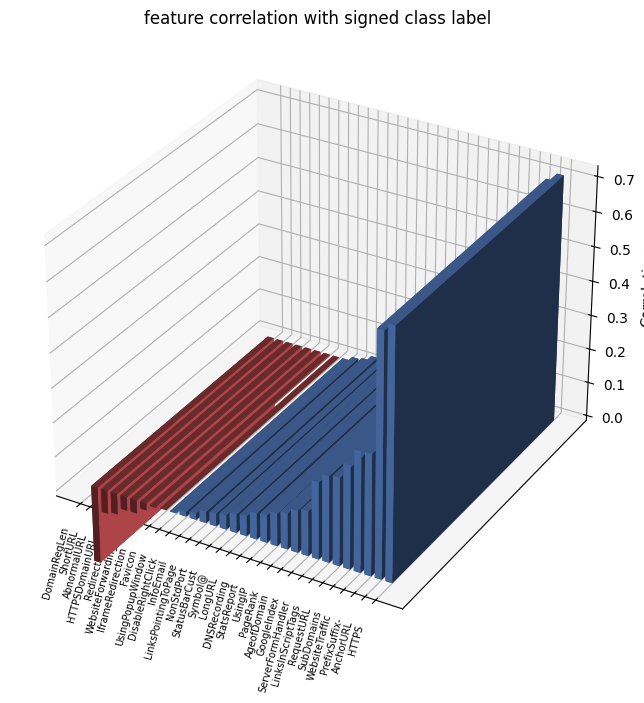

In [10]:
feature_target_corr = df[FEATURE_COLUMNS + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
display(feature_target_corr.rename("correlation_with_class").to_frame())
fig = plt.figure(figsize=(12, 8)); ax = fig.add_subplot(111, projection="3d")
x = np.arange(len(feature_target_corr)); heights = feature_target_corr.values
colors = ["#c44e52" if value < 0 else "#4c72b0" for value in heights]
ax.bar3d(x, np.zeros(len(x)), np.zeros(len(x)), 0.65, 0.65, heights, color=colors, shade=True)
ax.set_xticks(x + 0.3); ax.set_xticklabels(feature_target_corr.index, rotation=75, ha="right", fontsize=7)
ax.set_yticks([]); ax.set_zlabel("Correlation")
ax.set_title("feature correlation with signed class label")
plt.tight_layout(); plt.show()


## 6. Prepare X and y; exclude row identifier

Separate the 30 predictors (`X`) from the target (`y`) and drop the `Index` column. Built-in checks confirm the labels are exactly -1 and +1 and that all predictors are numeric, so bad input fails early with a clear message.

In [11]:
X = df.drop(columns=[TARGET] + [c for c in IDENTIFIER_COLUMNS if c in df.columns]).copy()
y = df[TARGET].copy()

if set(y.dropna().unique()) != {-1, 1}:
    raise ValueError(f"Expected target labels -1 and 1; found {sorted(y.dropna().unique())}")
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
    raise ValueError("Non-numeric predictors exist; inspect and encode them before modeling.")

FEATURE_COLUMNS = X.columns.tolist()
print(f"Using {len(FEATURE_COLUMNS)} numeric features.")
print("Phishing label = -1; legitimate label = +1.")


Using 30 numeric features.
Phishing label = -1; legitimate label = +1.


## 7. Stratified 80/20 train/test split

Split into 8,843 training and 2,211 test rows. Stratification keeps the phishing/legitimate proportions the same in both sets (about 44% / 56%). The test set is not used again until the final evaluation.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train rows:", len(X_train), " Test rows:", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename(index=class_names).to_frame("proportion"))
print("Test class proportions:")
display(y_test.value_counts(normalize=True).rename(index=class_names).to_frame("proportion"))


Train rows: 8843  Test rows: 2211
Training class proportions:


,proportion
class,
Legitimate,0.556938
Phishing,0.443062


Test class proportions:


,proportion
class,
Legitimate,0.557214
Phishing,0.442786


## 8. Preprocessing and baseline models

Build a reusable pipeline that applies median imputation and standard scaling, then the model. Because these steps are fitted inside each training fold, no information from validation or test rows leaks into preprocessing.

Three baseline models are compared: Logistic Regression (linear), Decision Tree (rule-based) and Random Forest (ensemble of trees).

In [13]:
def make_pipeline(model):
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), FEATURE_COLUMNS)
    ], remainder="drop")
    return Pipeline([("preprocessing", preprocessing), ("model", model)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}


## 9. Five-fold cross-validation on training data

Evaluate each model with stratified five-fold cross-validation on the training data only. Besides accuracy, the metrics focus on the **phishing class** (precision, recall, F1), because missing a phishing site is the costlier mistake.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision_phishing": make_scorer(precision_score, pos_label=PHISHING_LABEL, zero_division=0),
    "recall_phishing": make_scorer(recall_score, pos_label=PHISHING_LABEL, zero_division=0),
    "f1_phishing": make_scorer(f1_score, pos_label=PHISHING_LABEL, zero_division=0),
}


### Logistic Regression: five-fold cross-validation

Linear baseline. Scores vary the most between folds, which suggests the classes are not cleanly separable by a straight boundary.

In [15]:
lr_cv = cross_validate(make_pipeline(models["Logistic Regression"]), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
lr_cv_scores = pd.DataFrame({metric: lr_cv[f"test_{metric}"] for metric in scoring}, index=range(1, 6))
lr_cv_scores.index.name = "fold"
display(lr_cv_scores)


,accuracy,precision_phishing,recall_phishing,f1_phishing
fold,,,,
1,0.908988,0.918121,0.872449,0.894702
2,0.928773,0.922879,0.915816,0.919334
3,0.928208,0.936255,0.899235,0.917372
4,0.932127,0.932203,0.913155,0.922581
5,0.919683,0.913548,0.904215,0.908858


### Decision Tree: five-fold cross-validation

Captures non-linear rules and improves clearly on the linear model.

In [16]:
dt_cv = cross_validate(make_pipeline(models["Decision Tree"]), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
dt_cv_scores = pd.DataFrame({metric: dt_cv[f"test_{metric}"] for metric in scoring}, index=range(1, 6))
dt_cv_scores.index.name = "fold"
display(dt_cv_scores)


,accuracy,precision_phishing,recall_phishing,f1_phishing
fold,,,,
1,0.955342,0.950192,0.948980,0.949585
2,0.957038,0.949239,0.954082,0.951654
3,0.962125,0.963777,0.950255,0.956969
4,0.964932,0.958069,0.962963,0.960510
5,0.954751,0.961892,0.934866,0.948187


### Random Forest: five-fold cross-validation

Averages many trees and gives the highest and most consistent scores across folds.

In [17]:
rf_cv = cross_validate(make_pipeline(models["Random Forest"]), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
rf_cv_scores = pd.DataFrame({metric: rf_cv[f"test_{metric}"] for metric in scoring}, index=range(1, 6))
rf_cv_scores.index.name = "fold"
display(rf_cv_scores)


,accuracy,precision_phishing,recall_phishing,f1_phishing
fold,,,,
1,0.968909,0.972763,0.956633,0.964630
2,0.973997,0.980469,0.960459,0.970361
3,0.969474,0.975260,0.955357,0.965206
4,0.974548,0.975515,0.966794,0.971135
5,0.968326,0.972692,0.955300,0.963918


### Baseline cross-validation comparison

Combine the fold results into one table (mean and standard deviation) and a chart.

**Findings:** Random Forest leads on every metric (97.1% accuracy, 95.9% phishing recall), ahead of Decision Tree (95.9%, 95.0%) and Logistic Regression (92.4%, 90.1%). Its low standard deviation shows stable performance across folds.

In [18]:
cv_scores = pd.concat({
    "Logistic Regression": lr_cv_scores,
    "Decision Tree": dt_cv_scores,
    "Random Forest": rf_cv_scores,
}, names=["model", "fold"]).reset_index()
cv_summary = cv_scores.groupby("model")[list(scoring)].agg(["mean", "std"])
display(cv_summary.sort_values(("recall_phishing", "mean"), ascending=False))


accuracy           precision_phishing            \
                         mean       std               mean       std   
model                                                                  
Random Forest        0.971051  0.002975           0.975340  0.003162   
Decision Tree        0.958838  0.004475           0.956634  0.006651   
Logistic Regression  0.923556  0.009348           0.924601  0.009496   

                    recall_phishing           f1_phishing            
                               mean       std        mean       std  
model                                                                
Random Forest              0.958909  0.004884    0.967050  0.003418  
Decision Tree              0.950229  0.010181    0.953381  0.005198  
Logistic Regression        0.900974  0.017291    0.912569  0.011203

C:\Users\king\AppData\Local\Temp\ipykernel_15556\2136456544.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


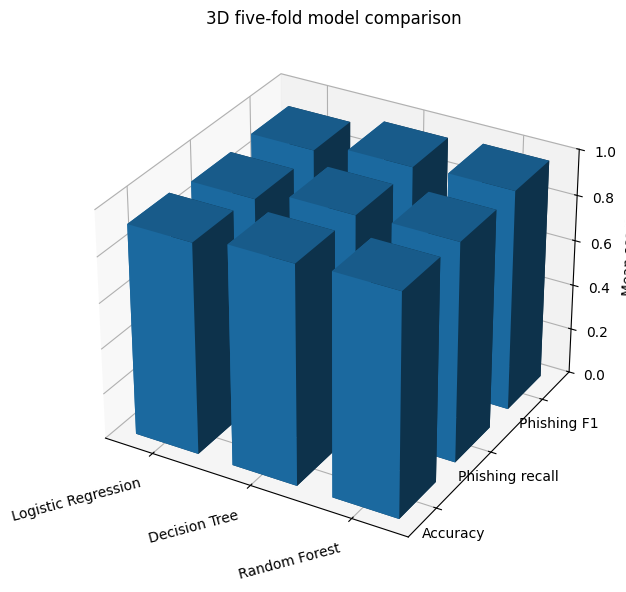

In [19]:
cv_plot = cv_scores.groupby("model")[["accuracy", "recall_phishing", "f1_phishing"]].mean()
metric_names = ["accuracy", "recall_phishing", "f1_phishing"]
model_names = list(models.keys()); means = cv_plot.reindex(model_names)
fig = plt.figure(figsize=(10, 7)); ax = fig.add_subplot(111, projection="3d")
xpos, ypos = np.meshgrid(np.arange(len(model_names)), np.arange(len(metric_names)), indexing="ij")
xpos, ypos = xpos.ravel(), ypos.ravel(); heights = means.values.ravel()
ax.bar3d(xpos, ypos, np.zeros(len(heights)), 0.65, 0.65, heights, shade=True, cmap="viridis")
ax.set_xticks(np.arange(len(model_names)) + 0.3); ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_yticks(np.arange(len(metric_names)) + 0.3); ax.set_yticklabels(["Accuracy", "Phishing recall", "Phishing F1"])
ax.set_zlim(0, 1); ax.set_zlabel("Mean score"); ax.set_title("3D five-fold model comparison")
plt.tight_layout(); plt.show()


## 10. Tune each model with GridSearchCV

Search a grid of hyperparameters for each model, scored on **phishing recall** with the same five folds. Including `class_weight` in the grid lets the search decide whether penalising missed phishing sites more helps. The test split remains untouched until final evaluation.

In [20]:
parameter_grids = {
    "Logistic Regression": {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    "Decision Tree": {"model__max_depth": [None, 5, 10, 20], "model__min_samples_leaf": [1, 3, 8], "model__class_weight": [None, "balanced"]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [None, 15, 30], "model__min_samples_leaf": [1, 3], "model__class_weight": [None, "balanced"]},
}
phishing_recall = make_scorer(recall_score, pos_label=PHISHING_LABEL, zero_division=0)


### Tune Logistic Regression

Tunes regularisation strength (`C`) and class weighting. Best cross-validated phishing recall: 0.914.

In [21]:
lr_search = GridSearchCV(make_pipeline(models["Logistic Regression"]), parameter_grids["Logistic Regression"], scoring=phishing_recall, cv=cv, n_jobs=-1, refit=True)
lr_search.fit(X_train, y_train)
print("Best CV phishing recall:", round(lr_search.best_score_, 4))
print("Best parameters:", lr_search.best_params_)


Best CV phishing recall: 0.9137
Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}


### Tune Decision Tree

Tunes tree depth, minimum leaf size and class weighting to limit overfitting. Best cross-validated phishing recall: 0.955.

In [22]:
dt_search = GridSearchCV(make_pipeline(models["Decision Tree"]), parameter_grids["Decision Tree"], scoring=phishing_recall, cv=cv, n_jobs=-1, refit=True)
dt_search.fit(X_train, y_train)
print("Best CV phishing recall:", round(dt_search.best_score_, 4))
print("Best parameters:", dt_search.best_params_)


Best CV phishing recall: 0.9548
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 1}


### Tune Random Forest

Tunes the number of trees, depth, leaf size and class weighting. Best cross-validated phishing recall: 0.964, using 400 trees with balanced class weights.

In [23]:
rf_search = GridSearchCV(make_pipeline(models["Random Forest"]), parameter_grids["Random Forest"], scoring=phishing_recall, cv=cv, n_jobs=-1, refit=True)
rf_search.fit(X_train, y_train)
print("Best CV phishing recall:", round(rf_search.best_score_, 4))
print("Best parameters:", rf_search.best_params_)


Best CV phishing recall: 0.9635
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


In [24]:
searches = {
    "Logistic Regression": lr_search,
    "Decision Tree": dt_search,
    "Random Forest": rf_search,
}


## 11. Compare tuned models and choose using training folds only

Rank the tuned models by cross-validated phishing recall and select the best one automatically. The decision uses training folds only, so the test set plays no part in model selection.

**Findings:** Random Forest is selected (0.964), ahead of Decision Tree (0.955) and Logistic Regression (0.914).

In [25]:
tuning_comparison = pd.DataFrame([
    {"model": name, "best_cv_phishing_recall": search.best_score_, "best_parameters": search.best_params_}
    for name, search in searches.items()
]).sort_values("best_cv_phishing_recall", ascending=False)
display(tuning_comparison)
best_model_name = tuning_comparison.iloc[0]["model"]
best_pipeline = searches[best_model_name].best_estimator_
print("Selected model:", best_model_name)


,model,best_cv_phishing_recall,best_parameters
2,Random Forest,0.963502,"{'model__class_weight': 'balanced', 'model__ma..."
1,Decision Tree,0.954825,"{'model__class_weight': 'balanced', 'model__ma..."
0,Logistic Regression,0.913736,"{'model__C': 1, 'model__class_weight': 'balanc..."


Selected model: Random Forest


C:\Users\king\AppData\Local\Temp\ipykernel_15556\536418080.py:8: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


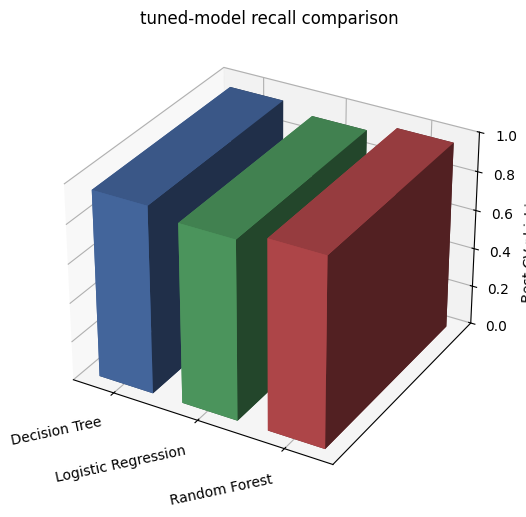

In [26]:
tuning_plot = tuning_comparison.sort_values("model")
fig = plt.figure(figsize=(8, 6)); ax = fig.add_subplot(111, projection="3d")
x = np.arange(len(tuning_plot)); heights = tuning_plot["best_cv_phishing_recall"].to_numpy()
ax.bar3d(x, np.zeros(len(x)), np.zeros(len(x)), 0.65, 0.65, heights, color=["#4c72b0", "#55a868", "#c44e52"], shade=True)
ax.set_xticks(x + 0.3); ax.set_xticklabels(tuning_plot["model"], rotation=12, ha="right")
ax.set_yticks([]); ax.set_zlim(0, 1); ax.set_zlabel("Best CV phishing recall")
ax.set_title("tuned-model recall comparison")
plt.tight_layout(); plt.show()


## 12. Final evaluation on the untouched test split

Evaluate the selected model once on the 2,211 held-out websites, which gives an unbiased estimate of real-world performance.

**Results:**

| Metric | Score |
|---|---|
| Accuracy | 97.47% |
| Phishing precision | 97.82% |
| Phishing recall | 96.42% |
| Phishing F1 | 97.12% |

Test performance matches the cross-validation results, which indicates the model generalises and is not overfitted.

In [27]:
y_pred = best_pipeline.predict(X_test)
test_metrics = {
    "selected_model": best_model_name,
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_phishing": precision_score(y_test, y_pred, pos_label=PHISHING_LABEL, zero_division=0),
    "recall_phishing": recall_score(y_test, y_pred, pos_label=PHISHING_LABEL, zero_division=0),
    "f1_phishing": f1_score(y_test, y_pred, pos_label=PHISHING_LABEL, zero_division=0),
}
display(pd.Series(test_metrics, name="final_test_result").to_frame())
print(classification_report(y_test, y_pred, labels=[-1, 1], target_names=["Phishing (-1)", "Legitimate (+1)"], zero_division=0))


,final_test_result
selected_model,Random Forest
accuracy,0.974672
precision_phishing,0.978238
recall_phishing,0.964249
f1_phishing,0.971193


                 precision    recall  f1-score   support

  Phishing (-1)       0.98      0.96      0.97       979
Legitimate (+1)       0.97      0.98      0.98      1232

       accuracy                           0.97      2211
      macro avg       0.98      0.97      0.97      2211
   weighted avg       0.97      0.97      0.97      2211



Confusion matrix (rows=true, columns=predicted; phishing then legitimate):
 [[ 944   35]
 [  21 1211]]


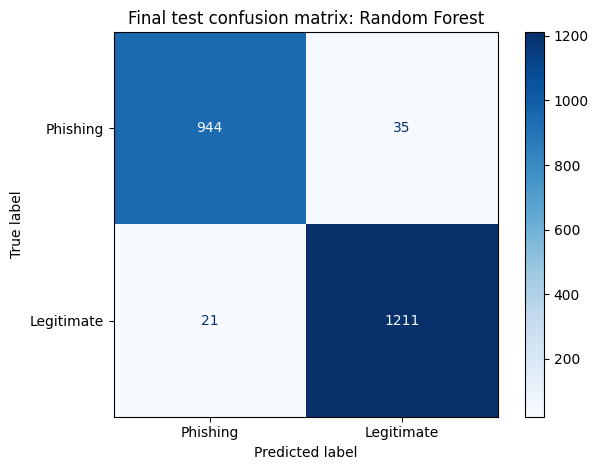

In [28]:
cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])
print("Confusion matrix (rows=true, columns=predicted; phishing then legitimate):\n", cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Phishing", "Legitimate"]).plot(cmap="Blues", values_format="d")
plt.title(f"Final test confusion matrix: {best_model_name}")
plt.tight_layout()
plt.show()


### View of the final confusion matrix

A 3D view of the same confusion matrix.

**Reading it:** 944 phishing sites were correctly caught and 1,211 legitimate sites were correctly passed. 35 phishing sites were missed and 21 legitimate sites were wrongly flagged. Overall, only 56 of 2,211 websites were misclassified.

C:\Users\king\AppData\Local\Temp\ipykernel_15556\35538290.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


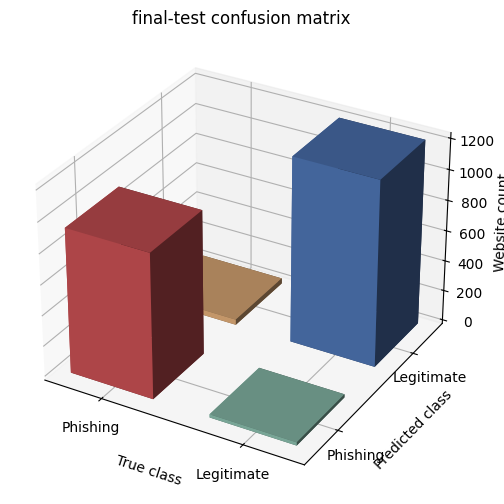

In [29]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
xpos, ypos = np.meshgrid(np.arange(2), np.arange(2), indexing="ij")
xpos, ypos = xpos.ravel(), ypos.ravel()
heights = cm.astype(float).ravel()
ax.bar3d(xpos, ypos, np.zeros(4), 0.6, 0.6, heights, color=["#c44e52", "#ddaa77", "#88bbaa", "#4c72b0"], shade=True)
ax.set_xticks(np.arange(2) + 0.3); ax.set_xticklabels(["Phishing", "Legitimate"])
ax.set_yticks(np.arange(2) + 0.3); ax.set_yticklabels(["Phishing", "Legitimate"])
ax.set_xlabel("True class"); ax.set_ylabel("Predicted class"); ax.set_zlabel("Website count")
ax.set_title("final-test confusion matrix")
plt.tight_layout()
plt.show()


## 13. Save the fitted pipeline and metadata

Save the full fitted pipeline (preprocessing and model) with its feature list and class mapping to `phishing_model.joblib`. Because the preprocessing is stored with the model, it can be reloaded and used without retraining.

In [30]:
artifact = {
    "pipeline": best_pipeline,
    "features": FEATURE_COLUMNS,
    "target": TARGET,
    "class_mapping": {"-1": "phishing", "1": "legitimate"},
    "selected_model": best_model_name,
}
joblib.dump(artifact, "phishing_model.joblib")
print("Saved phishing_model.joblib")


Saved phishing_model.joblib


## 14. Predict for new feature rows

`predict_feature_rows()` loads the saved model, checks that all 30 required columns are present and numeric, and returns the predicted label and the phishing probability for each row. The input must use the same definitions and numeric encodings as the training data. The notebook does not classify raw URL text.

In [31]:
def predict_feature_rows(new_rows, model_path="phishing_model.joblib"):
    saved = joblib.load(model_path)
    required = saved["features"]
    missing = sorted(set(required) - set(new_rows.columns))
    if missing:
        raise ValueError("Missing required feature columns: " + ", ".join(missing))
    features = new_rows.loc[:, required].apply(pd.to_numeric, errors="raise")
    fitted_pipeline = saved["pipeline"]
    labels = fitted_pipeline.predict(features)
    results = pd.DataFrame({
        "prediction": labels,
        "label": [saved["class_mapping"][str(int(label))] for label in labels],
    })
    if hasattr(fitted_pipeline, "predict_proba"):
        classes = list(fitted_pipeline.named_steps["model"].classes_)
        results["phishing_probability"] = fitted_pipeline.predict_proba(features)[:, classes.index(-1)]
    return results

# Example: create a feature-only row from the first record to see the interface.
example_features = X.iloc[[0]].copy()
display(predict_feature_rows(example_features))


,prediction,label,phishing_probability
0,-1,phishing,0.962083


### Interactive prediction

Enter the path to a CSV of extracted website features to get a prediction for each row.

In [34]:
# Interactive prediction: provide a CSV with one or more rows of extracted features.
# Raw URL strings cannot be classified by this dataset/model.
import pandas as pd
import re
from urllib.parse import urlparse

# Enter website URL
website_url = input("Enter Website URL: ").strip()

if not website_url:
    print("Please enter a website URL.")

else:
    if not website_url.startswith(("http://", "https://")):
        website_url = "https://" + website_url

    parsed = urlparse(website_url)

    if not parsed.hostname:
        print("Invalid URL.")

    else:
        try:
            # Extract website features
            user_features = extract_website_features(website_url)

            # Convert extracted features into DataFrame
            user_features = pd.DataFrame([user_features])

            # Predict malware
            prediction = model.predict(user_features)[0]

            # Get prediction probability
            probabilities = model.predict_proba(user_features)[0]

            # Find malware class probability
            malware_index = list(model.classes_).index(1)
            safe_index = list(model.classes_).index(0)

            malware_percentage = probabilities[malware_index] * 100
            safe_percentage = probabilities[safe_index] * 100

            print("\n========== MALWARE DETECTION ==========")
            print("Website:", website_url)

            if prediction == 1:
                print("Status: MALICIOUS WEBSITE")
            else:
                print("Status: SAFE / LEGITIMATE WEBSITE")

            print(f"Malware Probability: {malware_percentage:.2f}%")
            print(f"Safe Probability: {safe_percentage:.2f}%")

            print("=======================================")

        except Exception as e:
            print("Error:", e)

Error: name 'extract_website_features' is not defined


## 15. Conclusion

**Summary of results**

| Stage | Random Forest (selected) |
|---|---|
| 5-fold CV accuracy (baseline) | 97.1% |
| 5-fold CV phishing recall (tuned) | 96.4% |
| **Final test accuracy** | **97.47%** |
| Final test phishing precision / recall / F1 | 97.8% / 96.4% / 97.1% |

- Random Forest outperformed Logistic Regression and Decision Tree at every stage.
- Preprocessing was fitted inside pipelines and model selection used training folds only, so the test result is an unbiased estimate.
- Tuning targeted phishing recall because a missed phishing site is the costlier error. The model caught 944 of 979 phishing sites in the test set.
- The fitted pipeline is saved and can score new feature rows with a phishing probability.

**Limitations**
- The model works on pre-extracted features and cannot classify a raw URL directly.
- Results come from a single dataset and one train/test split; performance on newer phishing techniques may differ.
- 35 phishing sites in the test set were still missed, so it should support, not replace, other security measures.

**Future work**
- Add a feature-extraction step so the model can accept raw URLs
- Try gradient boosting (XGBoost, LightGBM)
- Add feature importance or SHAP explanations
- Adjust the decision threshold to trade precision against recall
- Deploy as a web app or browser extension and validate on fresh data